# 02 - Vectorization & Naive Bayes & Logistic Regression (B)

In [1]:
import sys
sys.path.append("..")
from src.evaluate import evaluate, save_results
from src.config import RESULTS

## Preparation

In [2]:
import pandas as pd
from src.config import *
from src.model import build_pipeline

from sklearn.feature_extraction.text import TfidfVectorizer

from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
from sklearn.model_selection import cross_val_score
from matplotlib import pyplot as plt

METRICS_CSV = RESULTS / "metrics_B.csv"
from sklearn.naive_bayes import MultinomialNB, ComplementNB




## Loading cleaned data

In [3]:
train = pd.read_csv(PROCESSED_DIR / "train.csv")
val = pd.read_csv(PROCESSED_DIR / "validation.csv")

train["text_clean"] = train["text_clean"].fillna("")
val["text_clean"] = val["text_clean"].fillna("")

X_train, y_train = train["text_clean"], train["label"]
X_val, y_val = val["text_clean"], val["label"]

print("train :", X_train.shape, "| val :", X_val.shape)

train : (2859,) | val : (955,)


# 1. Vectorization

## 1.1 create the TF-IDF vectorizer (the object that transforms text into numbers)

In [4]:
TOKEN_PATTERN = r"[\w']+|[^\w\s]"
vec = TfidfVectorizer(token_pattern=TOKEN_PATTERN, lowercase=False)
M_train = vec.fit_transform(X_train)     # fit to the train ONLY
M_val = vec.transform(X_val)

print("Matrice train :", M_train.shape)
print("Matrice val   :", M_val.shape)
print("Part de cases non nulles :", round(M_train.nnz / (M_train.shape[0] * M_train.shape[1]) * 100, 3), "%")

Matrice train : (2859, 9670)
Matrice val   : (955, 9670)
Part de cases non nulles : 0.148 %


## 1.2 Comparison of configurations
Why Logistic Regression? To compare the cleaning versions and vectorizer settings, we needed one fixed, simple model, so that any change in score comes from the preprocessing and not from the model. Logistic Regression is a strong baseline for text classification on sparse TF-IDF features, it is fast enough to test many configurations, and it is interpretable: it learns one weight per word, which lets us show the words that push towards irony or non-irony. It also serves as the reference against which the other models are compared.

,n_features,accuracy_val,f1_macro_val,f1_macro_cv_train
"BoW words (1,1)",9670,0.6230,0.6227,0.6205
"TF-IDF words (1,1)",9670,0.6325,0.6323,0.6126
"TF-IDF words (1,1) + sublinear_tf",9670,0.6220,0.6217,0.6152
"TF-IDF words (1,2)",41106,0.6283,0.6281,0.6142
"TF-IDF words (1,2) + min_df=2",6976,0.6346,0.6345,0.6192
"TF-IDF words (1,2) + min_df=2 + sublinear_tf",6976,0.6283,0.6281,0.6184
"TF-IDF char_wb (2,5)",83517,0.6272,0.6272,0.6252
"TF-IDF char_wb (2,5) + sublinear_tf",83517,0.6178,0.6178,0.6265
"TF-IDF char_wb (2,5) + min_df=2 + sublinear_tf",32923,0.6199,0.6196,0.6234


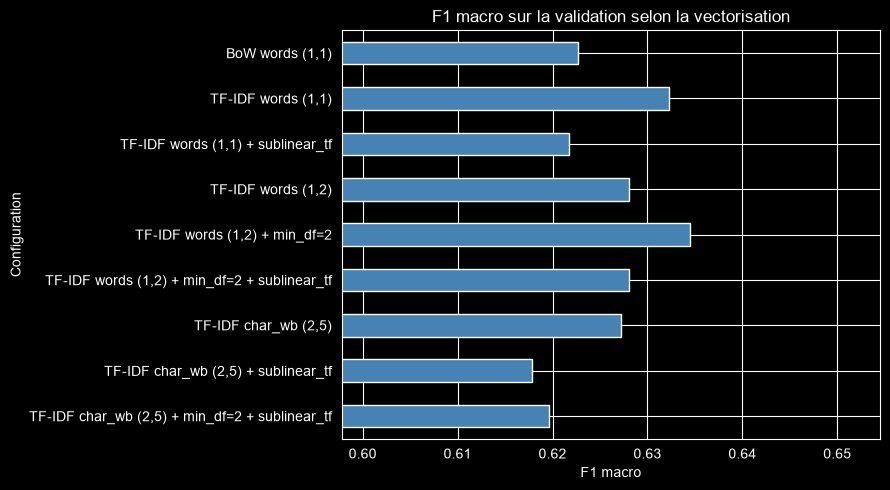

In [5]:
def faire_pipeline(vectorizer):
    return Pipeline([
        ("tfidf", vectorizer),
        ("clf", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
    ])

words = dict(token_pattern=TOKEN_PATTERN, lowercase=False)
chars = dict(analyzer="char_wb", ngram_range=(2, 5), lowercase=False)

configs = {
    "BoW words (1,1)": CountVectorizer(**words),
    "TF-IDF words (1,1)": TfidfVectorizer(**words),
    "TF-IDF words (1,1) + sublinear_tf": TfidfVectorizer(**words, sublinear_tf=True),
    "TF-IDF words (1,2)": TfidfVectorizer(**words, ngram_range=(1, 2)),
    "TF-IDF words (1,2) + min_df=2": TfidfVectorizer(**words, ngram_range=(1, 2), min_df=2),
    "TF-IDF words (1,2) + min_df=2 + sublinear_tf": TfidfVectorizer(**words, ngram_range=(1, 2), min_df=2, sublinear_tf=True),
    "TF-IDF char_wb (2,5)": TfidfVectorizer(**chars),
    "TF-IDF char_wb (2,5) + sublinear_tf": TfidfVectorizer(**chars, sublinear_tf=True),
    "TF-IDF char_wb (2,5) + min_df=2 + sublinear_tf": TfidfVectorizer(**chars, min_df=2, sublinear_tf=True),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

def tester(vectorizer):
    modele = faire_pipeline(vectorizer)
    modele.fit(X_train, y_train)
    pred = modele.predict(X_val)

    cv_f1 = cross_val_score(faire_pipeline(vectorizer), X_train, y_train, cv=cv, scoring="f1_macro").mean()

    return {
        "n_features": len(modele.named_steps["tfidf"].get_feature_names_out()),
        "accuracy_val": accuracy_score(y_val, pred),
        "f1_macro_val": f1_score(y_val, pred, average="macro"),
        "f1_macro_cv_train": cv_f1,
    }
resultats = pd.DataFrame({nom: tester(v) for nom, v in configs.items()}).T
resultats["n_features"] = resultats["n_features"].astype(int)
resultats = resultats.round(4)
display(resultats)

plt.figure(figsize=(9, 5))
resultats["f1_macro_val"].iloc[::-1].plot(kind="barh", color="steelblue")
plt.title("F1 macro sur la validation selon la vectorisation")
plt.xlabel("F1 macro")
plt.ylabel("Configuration")
plt.xlim(resultats["f1_macro_val"].min() - 0.02, resultats["f1_macro_val"].max() + 0.02)
plt.tight_layout()
plt.show()

We keep TF-IDF words (1,2) + min_df=2, which has the highest validation macro-F1 (about 0.634).
However, the differences between configurations are small (all scores fall between about 0.62 and 0.635), which is within the noise we expect on a validation set of 955 tweets. So the score alone does not prove that this configuration is better than the others.
We keep it for practical reasons: bigrams can capture short phrases such as "not happy", min_df=2 removes words that appear in only one tweet, and word-level features stay easy to interpret (we use them to look at the top words later). Character n-grams did not give any improvement.

## 1.3 Configuration retenue

In [6]:
#Finds the name of the configuration with the highest f1_macro_val in the results table
meilleure = resultats["f1_macro_val"].idxmax()
print("Configuration retenue :", meilleure)
print(resultats.loc[meilleure])
print()
print(configs[meilleure].get_params(deep=False))

Configuration retenue : TF-IDF words (1,2) + min_df=2
n_features           6976.0000
accuracy_val            0.6346
f1_macro_val            0.6345
f1_macro_cv_train       0.6192
Name: TF-IDF words (1,2) + min_df=2, dtype: float64

{'analyzer': 'word', 'binary': False, 'decode_error': 'strict', 'dtype': <class 'numpy.float64'>, 'encoding': 'utf-8', 'input': 'content', 'lowercase': False, 'max_df': 1.0, 'max_features': None, 'min_df': 2, 'ngram_range': (1, 2), 'norm': 'l2', 'preprocessor': None, 'smooth_idf': True, 'stop_words': None, 'strip_accents': None, 'sublinear_tf': False, 'token_pattern': "[\\w']+|[^\\w\\s]", 'tokenizer': None, 'use_idf': True, 'vocabulary': None}


## Verification

In [7]:
modele_final = build_pipeline(LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))
modele_final.fit(X_train, y_train)
pred = modele_final.predict(X_val)

print("F1 macro (validation) :", round(f1_score(y_val, pred, average="macro"), 4))
print("Table value           :", resultats.loc[meilleure, "f1_macro_val"])

F1 macro (validation) : 0.6345
Table value           : 0.6345


# 2. Naive Bayes

**Idea:** Naive Bayes uses how often each word appears in ironic vs non-ironic tweets, assuming the words are independent. It is the classic, very fast baseline for text.

## 2.1 Tuning alpha (smoothing)

Best parameters: {'clf': MultinomialNB(), 'clf__alpha': 2.0}
Best CV macro-F1: 0.6209


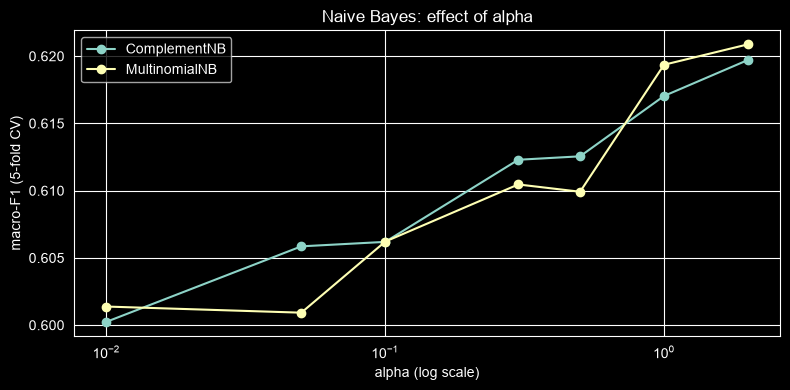

In [8]:
nb_grid = GridSearchCV(
    build_pipeline(MultinomialNB()),
    param_grid={
        "clf": [MultinomialNB(), ComplementNB()],
        "clf__alpha": [0.01, 0.05, 0.1, 0.3, 0.5, 1.0, 2.0],
    },
    cv=cv,
    scoring="f1_macro",
)
nb_grid.fit(X_train, y_train)

print("Best parameters:", nb_grid.best_params_)
print("Best CV macro-F1:", round(nb_grid.best_score_, 4))

nb_cv = pd.DataFrame(nb_grid.cv_results_)
nb_cv["model"] = nb_cv["param_clf"].astype(str).str.replace("()", "", regex=False)
nb_cv = nb_cv.rename(columns={"param_clf__alpha": "alpha", "mean_test_score": "f1_macro_cv", "std_test_score": "cv_std"})

plt.figure(figsize=(8, 4))
for name, group in nb_cv.groupby("model"):
    plt.plot(group["alpha"], group["f1_macro_cv"], marker="o", label=name)
plt.xscale("log")
plt.xlabel("alpha (log scale)")
plt.ylabel("macro-F1 (5-fold CV)")
plt.title("Naive Bayes: effect of alpha")
plt.legend()
plt.tight_layout()
plt.show()

## 2.2 Best Naitive Bayes

---MultinomialNB---
              precision    recall  f1-score   support

   non_irony      0.664     0.597     0.629       499
       irony      0.603     0.669     0.634       456

    accuracy                          0.631       955
   macro avg      0.633     0.633     0.631       955
weighted avg      0.635     0.631     0.631       955



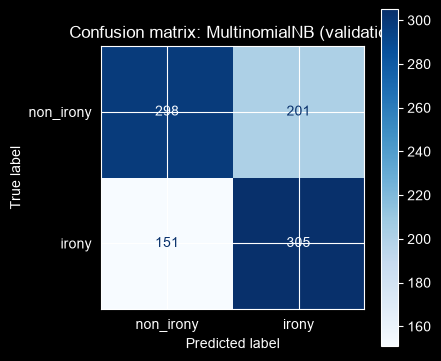

In [9]:
nb_best = nb_grid.best_estimator_          # already refitted on the whole training set
pred_nb = nb_best.predict(X_val)

nb_name = type(nb_best.named_steps["clf"]).__name__
nb_metrics = evaluate(nb_name, y_val, pred_nb)
save_results(nb_metrics, METRICS_CSV, **nb_grid.best_params_)

# 3.Logistic Regression

**Idea:** Logistic Regression learns **one weight per word**: positive weights push towards irony, negative weights towards non-irony; the sum decides the class. It is usually the strongest classical model for text, and fully interpretable.

## 3.1 Tuning "C" the inverse of regularization strength

In [10]:
lr_grid = GridSearchCV(
    build_pipeline(LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
    param_grid={
        "clf__C": [0.1, 0.3, 1, 3, 10],
        "clf__class_weight": [None, "balanced"],
    },
    cv=cv,
    scoring="f1_macro",
)
lr_grid.fit(X_train, y_train)

print("Best parameters:", lr_grid.best_params_)
print("Best CV macro-F1:", round(lr_grid.best_score_, 4))

pd.DataFrame(lr_grid.cv_results_)[
    ["param_clf__C", "param_clf__class_weight", "mean_test_score", "std_test_score"]
].round(4)


Best parameters: {'clf__C': 3, 'clf__class_weight': None}
Best CV macro-F1: 0.6226


,param_clf__C,param_clf__class_weight,mean_test_score,std_test_score
0,0.1,NaN,0.5803,0.0099
1,0.1,balanced,0.5912,0.0132
2,0.3,NaN,0.6014,0.0180
3,0.3,balanced,0.6033,0.0185
4,1.0,NaN,0.6192,0.0232
5,1.0,balanced,0.6174,0.0245
6,3.0,NaN,0.6226,0.0194
7,3.0,balanced,0.6217,0.0172
8,10.0,NaN,0.6132,0.0193
9,10.0,balanced,0.6143,0.0212


## 3.2 Evaluation of the best Logistic Regression on validation

---LogisticRegression---
              precision    recall  f1-score   support

   non_irony      0.668     0.645     0.656       499
       irony      0.626     0.649     0.637       456

    accuracy                          0.647       955
   macro avg      0.647     0.647     0.647       955
weighted avg      0.648     0.647     0.647       955



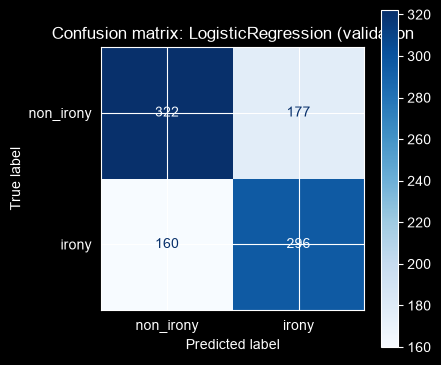

In [11]:
lr_best= lr_grid.best_estimator_
pred_lr=lr_grid.predict(X_val)

lr_metrics=evaluate("LogisticRegression", y_val, pred_lr)
save_results(lr_metrics,METRICS_CSV,**lr_grid.best_params_)

## 3.3 Which words push towards irony?

Logistic Regression gives one weight to each word (or pair of words). Positive weights push a tweet towards irony, negative weights towards non-irony. We plot the 20 strongest of each side.

In [ ]:
words = lr_best.named_steps["tfidf"].get_feature_names_out()
weights = lr_best.named_steps["clf"].coef_[0]

coef = pd.Series(weights, index=words).sort_values()
top_irony = coef.tail(20)
top_non_irony = coef.head(20)

fig, axes = plt.subplots(1, 2, figsize=(13, 6))
top_irony.plot(kind="barh", ax=axes[0], color="indianred")
axes[0].set_title("Top 20 words → irony")
axes[0].set_xlabel("weight")
top_non_irony.plot(kind="barh", ax=axes[1], color="steelblue")
axes[1].set_title("Top 20 words → non_irony")
axes[1].set_xlabel("weight")
plt.tight_layout()
plt.show()

**Observation.** The words that push towards irony are mostly **positive words** (*great, I love, fun, Yay, thanks for*) and words about **unpleasant situations** (*Monday, test*), plus the 😒 emoji. This is the classic pattern of verbal irony: saying something positive about something negative ("I love Mondays"). The model only sees words, so it cannot tell a sincere "I love" from an ironic one — which limits all bag-of-words models.

Surprisingly, *not* pushes strongly towards **non**-irony. This is a side effect of how the dataset was built: the hashtag **#not** was deleted from ironic tweets, so the word "not" survives mostly in non-ironic tweets.

# 4. Conclusion

| Model | Settings (5-fold CV on train) | CV macro-F1 | Validation macro-F1 |
|---|---|---|---|
| Multinomial Naive Bayes | alpha = 2.0 | 0.621 | 0.631 |
| **Logistic Regression** | C = 3, no class weight | 0.623 | **0.647** |

- **Vectorization:** the nine configurations tested are within about 0.015 of each other, less than the cross-validation noise (std ≈ 0.02). We kept TF-IDF on words, unigrams + bigrams, `min_df=2`: as good as the others, simpler, and interpretable.
- **Both models are close.** Logistic Regression is slightly better on validation, and it is fully interpretable: its weights show which words signal irony.
- **Limit:** both models only count words. Irony depends on tone and context ("I love Mondays"), which a bag of words cannot see. This motivates the transformer of notebook 04.
- The test set is not used here: all models are evaluated on it together in notebook 05.